# Supplementary Fig. 5b: predicted spike assignment biases among 'single-units', by spike sorter

**author**: laquitainesteeve@gmail.com

**purpose**: reproduce panel b of Supplementary Fig. 5: ratios of the spike assignment biases of the sorted 'single-units' by layer (x-axis), spike sorter (columns) and ground truth simulation (rows: S, synthetic model; NS, biophysical spontaneous; DS, dense probe biophysical spontaneous; E, biophysical evoked). The overlaid numbers are the numbers of units. Source data and svg are saved in figures/8_source_data/supp_fig5b/.

**data**: `dataset/01_intermediate/quality/sorting_quality.csv`, the quality (spike assignment bias, from the comparison of each sorted unit with the ground truth units) of the 'single-units' sorted from the first 10 minutes of each simulated recording, one row per sorted unit. Biases: partial (oversplitter), good + partial, merged + partial (overmerger + oversplitter), good + merged + partial and false positive. Units outside the cortex are dropped.

In [1]:
# SETUP PACKAGES
import os
import warnings
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
warnings.simplefilter(action="ignore")

# SET PROJECT PATH
PROJ_PATH = "/home/steeve/steeve/epfl/code/spikebias"
os.chdir(PROJ_PATH)
from src.nodes.metrics import quality

# pre-computed intermediate dataset: quality (spike assignment bias) of each sorted unit
QUALITY_PATH = "dataset/01_intermediate/quality/sorting_quality.csv"

# PARAMETERS
SORTERS = ["KS4", "KS3", "KS2.5", "KS2", "KS", "HS"]
SORTER_TITLES = ["Kilosort4", "Kilosort3", "Kilosort2.5", "Kilosort2", "Kilosort", "Herdingspikes"]
EXPERIMENTS = ["S", "NS", "DS", "E"]
LAYERS = ["L1", "L2/3", "L4", "L5", "L6"]

# FIGURE SETTINGS
plt.rcParams["font.family"] = "DejaVu Sans"   # the paper's figure was drawn without Arial (matplotlib default font)
plt.rcParams["font.size"] = 6  # 5-7 with Nature neuroscience as reference
plt.rcParams["lines.linewidth"] = 0.5
plt.rcParams["axes.linewidth"] = 0.5
plt.rcParams["axes.spines.top"] = False
plt.rcParams["xtick.major.width"] = 0.5
plt.rcParams["ytick.major.width"] = 0.5
plt.rcParams["xtick.major.size"] = 3.5 * 1.1
plt.rcParams["ytick.major.size"] = 3.5 * 1.1
savefig_cfg = {"transparent": True, "dpi": 300}

## Load the dataset and count the units

In [2]:
df = pd.read_csv(QUALITY_PATH)
df = df[df["layer"].isin(LAYERS)]          # units in cortex
df_counts = df.groupby(["sorter", "experiment", "layer", "quality"]).size().reset_index(name="count")
display(df_counts.groupby(["sorter", "experiment"])["count"].sum().unstack().loc[SORTERS, EXPERIMENTS])

experiment,S,NS,DS,E
sorter,,,,
KS4,377,184,197,407
KS3,349,233,243,499
KS2.5,413,578,452,632
KS2,1512,1187,752,458
KS,1254,1806,1484,2642
HS,230,199,160,206


## Plot, same as the paper's panel b

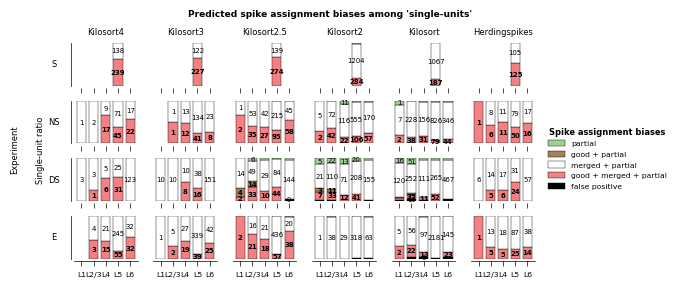

In [3]:
def plot_source_data(df_counts: pd.DataFrame):
    """Ratios of spike assignment biases among single-units by layer, spike sorter and experiment"""
    fig, axes = quality.plot_spike_assignment_biases_grid(df_counts, SORTERS, SORTER_TITLES, EXPERIMENTS, LAYERS)
    fig.suptitle("Predicted spike assignment biases among 'single-units'", fontsize=6.5, fontweight="bold", y=1.0)
    return fig


fig = plot_source_data(df_counts)

## Save the figure and the source data

In [4]:
os.makedirs("figures/8_source_data/supp_fig5b", exist_ok=True)
plt.savefig("figures/8_source_data/supp_fig5b/supp_fig5b.svg", bbox_inches="tight", **savefig_cfg)
df_counts.to_excel("figures/8_source_data/supp_fig5b/supp_fig5b.xlsx", index=False)

<Figure size 640x480 with 0 Axes>

## Check: replot from the saved source data

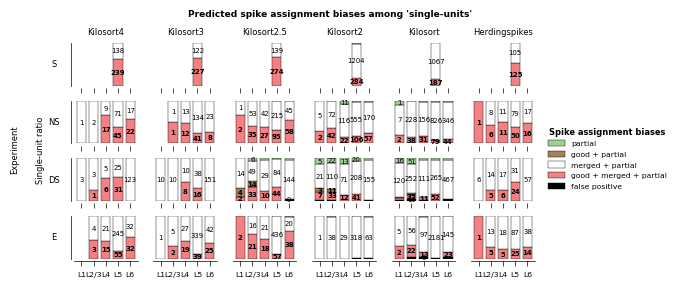

In [5]:
df_counts_loaded = pd.read_excel("figures/8_source_data/supp_fig5b/supp_fig5b.xlsx")
fig = plot_source_data(df_counts_loaded)